# Toy problem to demonstrate theory of ACFs

Take
$$
 C_u(\tau) = \frac{\langle u(x_t)u(x_{t+\tau}\rangle}{\langle u(x_t)^2\rangle} = \sum_{i\ge 1} a_i \text{e}^{-\tau/\tau_i}
$$

The model is based on the solvated alanine dipeptide with estimates for TRUE eigenvalues being
$$
\tau_1 = 1440~\text{ps}\hspace{0.5cm}
\tau_2 = 60~\text{ps}\hspace{0.5cm}
\tau_3 = 26~\text{ps}\hspace{0.5cm}
\tau_4 = 2~\text{ps}
$$
Because the TRUE eigenfunction $\psi_1(x)$ involves solvent df which are not represented in our SRV model, what we are actually computing is an estimate.  This estimate is correctly written as a sum of pure exponentials.  Because the timescales are dropping so rapidly, we will approximate our estimate for the true ACF as (prefactors have been chosen somewhat arbitrarily, but we hope to mostly capture the true exponential of $C_1$):
$$
\hat{C}_1(\tau) = 0.7\,\text{e}^{-\tau/1440} + 0.1\,\text{e}^{-\tau/60} + 0.1\,\text{e}^{-\tau/26} + 0.1\,\text{e}^{-\tau/2}
$$

We now proceed to use this toy system to get a sense for what we can expect from our computed ACF, $\hat{C}_1(\tau)$.

## 1. $\hat{C}_1(\tau)$ is dominated by the slow $\psi_1$ process, EXCEPT at small $\tau$

Look at contribution of each term $a_i\text{e}^{-\tau/\tau_i}$ and $\log C_n(\tau)$ where $C_n(\tau) = \sum_{i=1}^n a_i\text{e}^{-\tau/\tau_i}$
to see convergence 

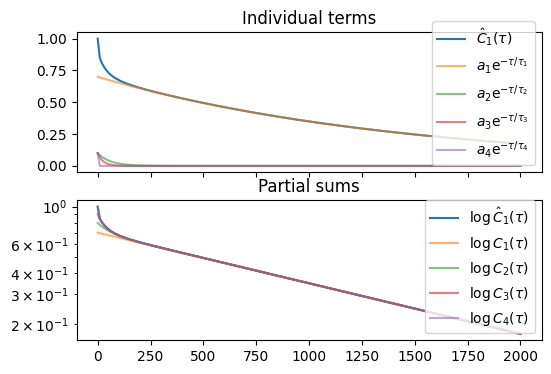

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from src.dataclass import DataClass


def toy_model_acf(taus, timescales=(1440, 60, 26, 2), coeffs=(0.7, 0.1, 0.1, 0.1)):
    """timescales in ps; amps are a_i (= c_i^2), sum to 1 so C(0) = 1."""
    terms = [a * np.exp(-taus / ti) for a, ti in zip(coeffs, timescales)]
    return DataClass(
        timescales=np.array(timescales),
        coeffs=np.array(coeffs),
        terms=terms,
        ct=np.sum(terms, axis=0),
    )


def plot_acf_terms(taus, acf):
    fig, axs = plt.subplots(2, 1, figsize=(6, 4), sharex=True)

    axs[0].set_title("Individual terms")
    axs[1].set_title("Partial sums")

    axs[0].plot(taus, acf.ct, label=r"$\hat{C}_1(\tau)$")
    axs[1].semilogy(taus, acf.ct, label=r"$\log\hat{C}_1(\tau)$")

    ctsum = np.zeros(taus.shape)
    for i, term in enumerate(acf["terms"]):
        label = r"$a_{%d}\mathrm{e}^{-\tau/\tau_{%d}}$" % (i + 1, i + 1)
        axs[0].plot(taus, term, label=label, alpha=0.6)

        ctsum += term
        label = r"$\log C_{%d}(\tau)$" % (i + 1)
        axs[1].semilogy(taus, ctsum, alpha=0.6, label=label)

    axs[0].legend()
    axs[1].legend()


taus = np.linspace(0, 2000, 200)
acf = model_acf(taus)
plot_acf_terms(taus, acf)

## 2. Computing $\tau_0$, $\tau_\mathrm{int}$, $\tau_\mathrm{exp}$

See `10.06.timescales_acf_analysis` in the `vac-metad` vault.

| Timescale              | Definition                    | In terms of the tᵢ         | What it tells you                                             |
| ---------------------- | ----------------------------- | -------------------------- | ------------------------------------------------------------- |
| Initial decay time τ₀  | −1 / C′(0)                    | harmonic mean, 1/Σ(aᵢ/tᵢ)  | How fast u starts to decorrelate; dominated by fast processes |
| Integrated time τ_int  | ∫₀^∞ C_u(τ) dτ                | arithmetic mean, Σ aᵢtᵢ    | Statistical cost: Var(time average of u) ≈ 2τ_int·σ²_u / T    |
| Exponential time τ_exp | decay time of the tail of C_u | the largest tᵢ with aᵢ > 0 | The slowest process u can see                                 |


### 2.A. Adding fast processes pulls $\tau_0$ downward
$$
\tau_0 = -\frac{1}{\hat{C}'_1(\tau)}
= -\frac{1}{\sum_{i\ge 1}a_i/\tau_i}
$$

In [10]:
def print_tau0(ratios, num_terms):
    tau0 = 1 / np.sum(ratios[:num_terms])
    print(f"{num_terms} terms: tau_0 = {tau0:.1f} ps")


ratios = acf["coeffs"] / acf["timescales"]
print(f"true tau_1 = {acf["timescales"][0]} ps")
for num_terms in range(1, 5):
    print_tau0(ratios, num_terms)

true tau_1 = 1440 ps
1 terms: tau_0 = 2057.1 ps
2 terms: tau_0 = 464.5 ps
3 terms: tau_0 = 166.7 ps
4 terms: tau_0 = 17.9 ps


### 2.B $\tau_\text{int}<\tau_1$ due to coefficient $a_1<1$
$$
\tau_\text{int} = \int_0^\infty d\tau \hat{C}_1(\tau)
= \sum_{i\ge 1}a_i\tau_i
$$
* as a weighted average, adding further terms raises $\tau_\text{int}$ closer to $\tau_1$, but it doesn't get there.
* the only way to get $\tau_\text{int}=\tau_1$ is for all $\tau_{i>1} = \tau_1$

In [11]:
def print_tau0(products, num_terms):
    tau = np.sum(products[:num_terms])
    print(f"{num_terms} terms: tau_int = {tau:.1f} ps")


products = acf["coeffs"] * acf["timescales"]
print(f"true tau_1 = {acf["timescales"][0]} ps")
for num_terms in range(1, 5):
    print_tau0(products, num_terms)

true tau_1 = 1440 ps
1 terms: tau_int = 1008.0 ps
2 terms: tau_int = 1014.0 ps
3 terms: tau_int = 1016.6 ps
4 terms: tau_int = 1016.8 ps


### 2.C Best estimator for $\tau_1$ using $\hat{C}_1(\tau)$
$$
\frac{d}{d\tau}\log\hat{C}_1(\tau) = \frac{1}{\hat{C}_1(\tau)}\sum_{i=1}^4 -\frac{a_i}{\tau_i}\text{e}^{-\tau/\tau_i}
$$
Now, go out sufficiently far that only the $a_1$ terms survive:
$$
\frac{d}{d\tau}\log\hat{C}_1(\tau) \approx \frac{1}{a_1\text{e}^{-\tau/\tau_1}}\left(-\frac{a_1}{\tau_1}\right)\text{e}^{-\tau/\tau_1}
= -\frac{1}{\tau_1}
$$
So, check the estimator: choose $\tau$ sufficiently large s.t. $\text{e}^{-\tau/\tau_1}\gg\text{e}^{-\tau/\tau_2}$ and take
$$
\hat{\tau}_1(\tau) = -\left[\frac{d}{d\tau}\log\hat{C}_t(\tau)\right]^{-1}
$$
where the derivatives are computed numerically from $\log\hat{C}_t(\tau)$

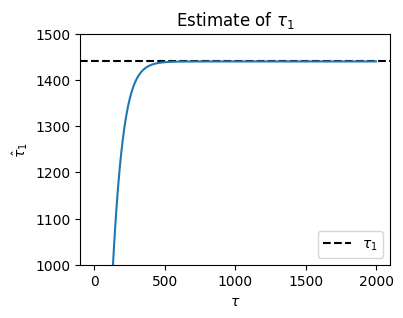

In [12]:
def plot_tau1_estimate(taus, ct):
    slope = np.gradient(np.log(ct), taus)  # d ln C / d tau
    tau_hat = -1.0 / slope  # local estimate of tau_1 at each lag

    fig, ax = plt.subplots(1, 1, figsize=(4, 3))
    ax.axhline(acf["timescales"][0], color="k", linestyle="--", label=r"$\tau_1$")
    ax.plot(taus, tau_hat)
    ax.set_xlabel(r"$\tau$")
    ax.set_ylabel(r"$\hat{\tau}_1$")
    ax.set_ylim(1000, 1500)
    ax.legend()
    ax.set_title(r"Estimate of $\tau_1$")


plot_tau1_estimate(taus, acf["ct"])

## 3. Bias of $\hat{\tau}_1(\tau)$

**Weighted-rate form.** For $C(\tau)=\sum_i a_i e^{-\tau/\tau_i}$:

$$
\frac{1}{\hat\tau_1(\tau)} = \sum_i w_i(\tau)\,\frac{1}{\tau_i},
\qquad w_i(\tau) = \frac{a_i e^{-\tau/\tau_i}}{C(\tau)}
$$

i.e. a $w$-weighted mean of rates; $\hat\tau_1 \to \tau_1$ as $w_1 \to 1$.

**Exact properties** (all $a_i = c_i^2 \ge 0$):
- $\hat\tau_1(\tau) \le \tau_1$ (lower bound)
- $\frac{d}{d\tau}\big(1/\hat\tau_1\big) = -\mathrm{Var}_w(1/\tau_i) \le 0$ $\Rightarrow$ $\hat\tau_1$ monotone increasing

**Asymptotic error** ($\tau_2$ dominates):

$$
\varepsilon(\tau) \equiv 1-\frac{\hat\tau_1}{\tau_1} \approx \frac{a_2}{a_1}\left(\frac{\tau_1}{\tau_2}-1\right)e^{-\tau/\tau_2'},
\qquad \tau_2' = \frac{\tau_1\tau_2}{\tau_1-\tau_2}\approx\tau_2
$$

**Rule:**

$$
\tau^* \approx \tau_2'\,\ln\!\left[\frac{a_2}{a_1}\left(\frac{\tau_1}{\tau_2}-1\right)\frac{1}{\varepsilon}\right]
$$

Required lag is set by $\tau_2$, not $\tau_1$. Model values: $\varepsilon=1\% \Rightarrow \tau^*\approx 363$ ps; $\varepsilon=0.1\% \Rightarrow \tau^*\approx 507$ ps.


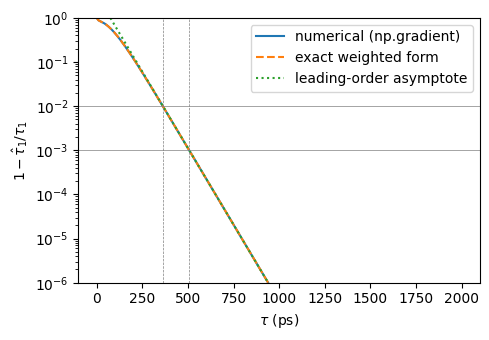

In [18]:
import numpy as np
import matplotlib.pyplot as plt

timescales = np.array([1440, 60, 26, 2.0])  # ps
amps = np.array([0.7, 0.1, 0.1, 0.1])  # a_i

taus = np.linspace(0, 2000, 4001)
terms = amps[:, None] * np.exp(-taus[None, :] / timescales[:, None])
ct = terms.sum(axis=0)

# your estimator: local slope of log C
tau1_hat = -1.0 / np.gradient(np.log(ct), taus)
rel_err = 1.0 - tau1_hat / timescales[0]

# exact weighted-rate form: 1/tau_hat = sum_i w_i / tau_i
w = terms / ct
rel_err_exact = 1.0 - 1.0 / (timescales[0] * (w / timescales[:, None]).sum(axis=0))

# leading-order asymptote: eps ~ (a2/a1)(tau1/tau2 - 1) exp(-tau/tau2')
t1, t2 = timescales[0], timescales[1]
tau2p = t1 * t2 / (t1 - t2)
A = (amps[1] / amps[0]) * (t1 / t2 - 1)
rel_err_asym = A * np.exp(-taus / tau2p)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogy(taus, rel_err, label="numerical (np.gradient)")
ax.semilogy(taus, rel_err_exact, "--", label="exact weighted form")
ax.semilogy(taus, rel_err_asym, ":", label="leading-order asymptote")
for eps in (1e-2, 1e-3):
    ax.axhline(eps, color="grey", lw=0.5)
    ax.axvline(tau2p * np.log(A / eps), color="grey", lw=0.5, ls="--")
ax.set_ylim(1e-6, 1)
ax.set_xlabel(r"$\tau$ (ps)")
ax.set_ylabel(r"$1 - \hat{\tau}_1/\tau_1$")
ax.legend()
fig.tight_layout()